In [9]:
from datasets import load_dataset
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
import os

In [10]:
# Dataset ID
dataset_id = "UBC-SLIME/colx585_group_project_data"

In [11]:
# Load dataset
dataset = load_dataset(dataset_id)

'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: eef831a5-39af-49fa-afe9-06cd85e61751)')' thrown while requesting HEAD https://huggingface.co/datasets/UBC-SLIME/colx585_group_project_data/resolve/main/README.md
Retrying in 1s [Retry 1/5].
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 94826ad4-ca82-4eae-b59f-0847dd787243)')' thrown while requesting HEAD https://huggingface.co/datasets/UBC-SLIME/colx585_group_project_data/resolve/e567d3542efc09da1ca3525daa0d8f39d55bab82/README.md
Retrying in 1s [Retry 1/5].


In [12]:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'is_member', 'type', 'text'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['id', 'image', 'is_member', 'type', 'text'],
        num_rows: 1200
    })
    test: Dataset({
        features: ['id', 'image', 'is_member', 'type', 'text'],
        num_rows: 6000
    })
})

# Exploring Samples

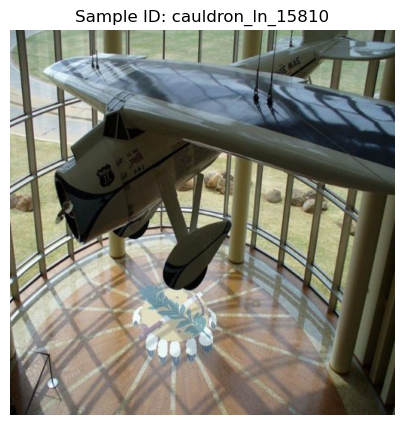


Sample 1
ID: cauldron_ln_15810
Text: Please provide a concise description of this image.
At the top of this image, there is aircraft attached to the threads. Below this aircraft, there is a floor of a building having windows and pillars. In the background, there are rocks, a road and grass on the ground.
Type: unseen_both
Is Member: 0
Saved Image Path: images/sample_0.png



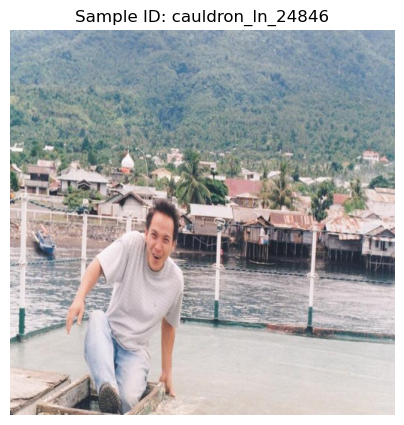


Sample 2
ID: cauldron_ln_24846
Text: In one or two sentences, can you explain what this image depicts?
In this image I can see houses and trees lake visible in the middle and I can see a person visible in the foreground ,at the top I can see the hill. In the middle I can see poles.
Type: unseen_both
Is Member: 0
Saved Image Path: images/sample_1.png



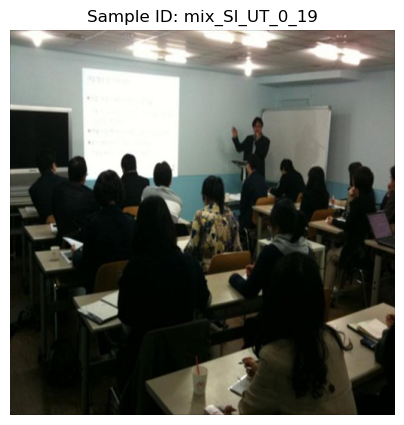


Sample 3
ID: mix_SI_UT_0_19
Text: Could you give a brief overview of what you see in this image?
In this image we can see a few people, among them some are riding the bicycles on the road, in the background, we can see a building with windows and there are some plants.
Type: seen_img_unseen_txt
Is Member: 0
Saved Image Path: images/sample_2.png



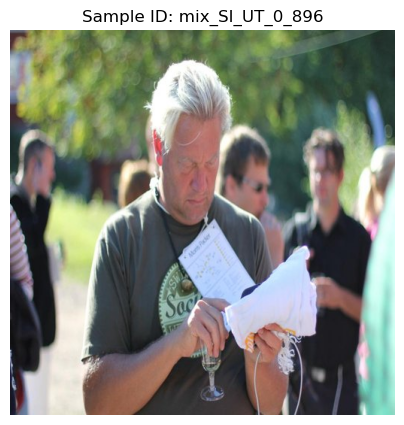


Sample 4
ID: mix_SI_UT_0_896
Text: Describe this image in one or two sentences.
This picture describes about group of people, in the left side of the image we can see a man, he is holding a guitar, in the middle of the image we can see another man, he is holding a microphone, in the background we can find few musical instruments, metal rods and lights.
Type: seen_img_unseen_txt
Is Member: 0
Saved Image Path: images/sample_3.png



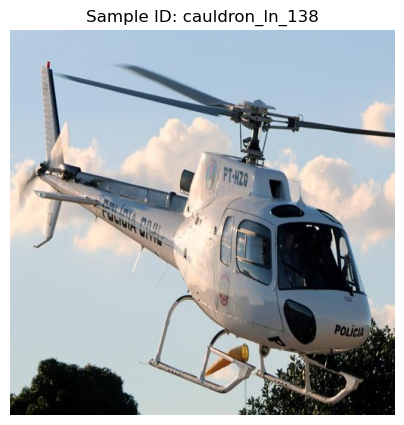


Sample 5
ID: cauldron_ln_138
Text: Can you describe this image briefly?
In this picture there is a man who is driving a helicopter. At the bottom I can see the trees. In the background I can see the sky and clouds.
Type: seen_both
Is Member: 1
Saved Image Path: images/sample_4.png



In [29]:
os.makedirs("images", exist_ok=True)
for i in range(5):
    example = dataset["train"][i]

    if isinstance(example["image"], dict) and "bytes" in example["image"]:
        image = Image.open(io.BytesIO(example["image"]["bytes"])).convert("RGB")
    else:
        image = example["image"].convert("RGB")

    image_path = f"images/sample_{i}.png"
    image.save(image_path)
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Sample ID: {example['id']}")
    plt.show()
    print("\n" + "="*60)
    print(f"Sample {i+1}")
    print(f"ID: {example['id']}")
    print(f"Text: {example['text']}")
    print(f"Type: {example['type']}")
    print(f"Is Member: {example['is_member']}")
    print(f"Saved Image Path: {image_path}")
    print("="*60 + "\n")

# Descriptive Statistics

In [30]:
stats = []
for split in dataset.keys():
    data = dataset[split]
    lengths = [len(x["text"].split()) for x in data]
    stats.append({
        "Split": split,
        "Number of samples": len(data),
        "Mean Length": round(np.mean(lengths), 2),
        "Max Length": np.max(lengths),
        "Min Length": np.min(lengths),
    })
df = pd.DataFrame(stats)
print(df)

        Split  Number of samples  Mean Length  Max Length  Min Length
0       train               6000        45.22         162          13
1  validation               1200        44.22         140          12
2        test               6000        45.05         208          10


# Data Visualization

## Membership Distribution

In [31]:
for split in ["train", "validation"]:
    data = dataset[split]
    members = sum(x["is_member"] == 1 for x in data)
    non_members = sum(x["is_member"] == 0 for x in data)
    print(f"\n--- {split} ---")
    print(f"Non-members (0): {non_members}")
    print(f"Members (1): {members}")
    print(f"Ratio (Non-member : Member) = {round(non_members/members, 2)} : 1")


--- train ---
Non-members (0): 4500
Members (1): 1500
Ratio (Non-member : Member) = 3.0 : 1

--- validation ---
Non-members (0): 900
Members (1): 300
Ratio (Non-member : Member) = 3.0 : 1


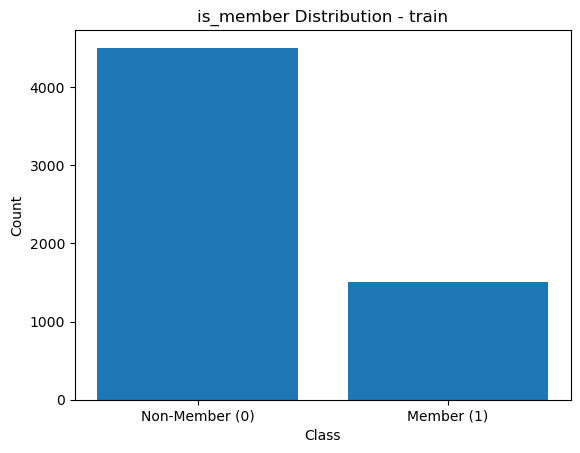

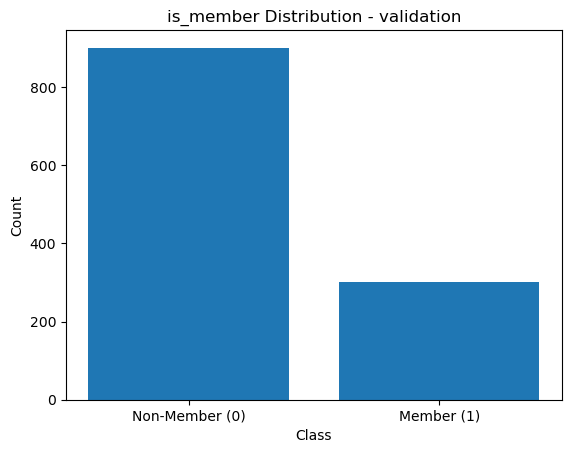

In [32]:
splits_to_plot = ["train", "validation"]
for split in splits_to_plot:
    data = dataset[split]
    members = sum(x["is_member"] == 1 for x in data)
    non_members = sum(x["is_member"] == 0 for x in data)
    plt.figure()
    plt.bar(["Non-Member (0)", "Member (1)"], [non_members, members])
    plt.title(f"is_member Distribution - {split}")
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.show()

# Type Distribution

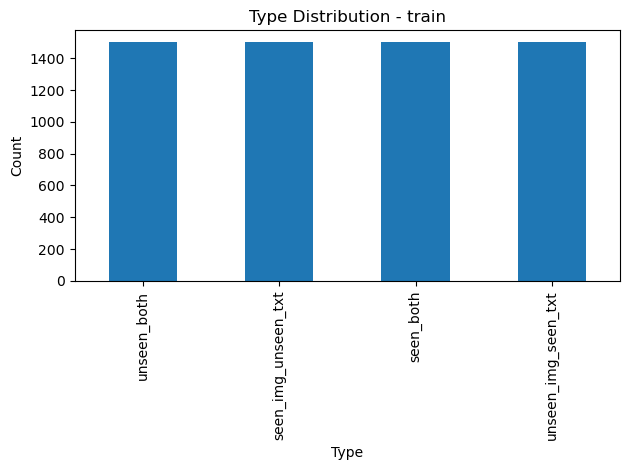

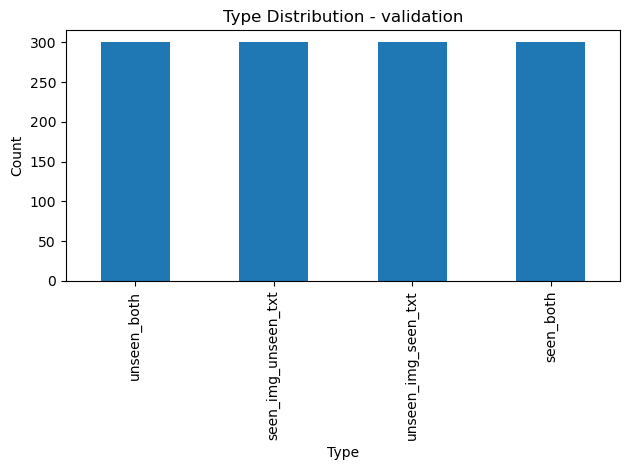

In [33]:
for split in ["train", "validation"]:
    data = dataset[split]
    types = [x["type"] for x in data]
    counts = pd.Series(types).value_counts()
    plt.figure()
    counts.plot(kind="bar")
    plt.title(f"Type Distribution - {split}")
    plt.xlabel("Type")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Text Length Distribution

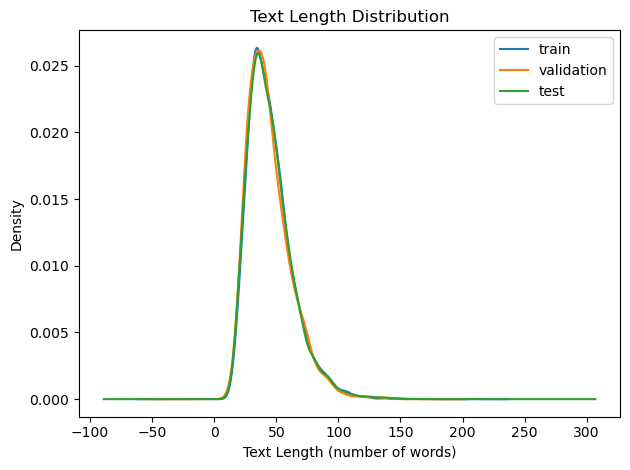

In [34]:
splits_to_plot = ["train", "validation", "test"]
plt.figure()

for split in splits_to_plot:
    data = dataset[split]
    lengths = [len(x["text"].split()) for x in data]
    pd.Series(lengths).plot(kind="kde", label=split)
plt.title("Text Length Distribution")
plt.xlabel("Text Length (number of words)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()